# 973. K Closest Points to Origin
**Difficulty:** 🟡 Medium · **Topic:** Heap · **Pattern:** [Top K](README.md) · **LeetCode:** https://leetcode.com/problems/k-closest-points-to-origin/

## 💡 Concepts

**Core concept(s):** **Top K with a size-k max-heap** keyed by distance — keep the `k` closest points seen so far; the farthest of them is the one to evict next.

**Why it applies here:**
- We want the `k` **smallest** distances out of `n`, in any order. That is a Top-K question.
- Only the `k` closest points matter; a point farther than all of the current `k` can be dropped at once.
- The "k smallest" direction needs a **max**-heap: its root is the farthest of the current `k`, the first to be pushed out.

**Key intuition:**
- Walk the points once. Each one tries to get into a group of `k` seats.
- If the group overflows, the **farthest** point in it leaves.
- After the walk, the group is the answer.

---

### 📚 What is Squared Euclidean Distance?
- The distance from `(x, y)` to the origin is `√(x² + y²)`.
- Square root only grows with its input, so comparing `x² + y²` gives the **same order** as comparing true distances.
- Skip `sqrt`: integer math is exact and faster.

### 📚 What is a Heap / Priority Queue?
- A **priority queue** is a bag of items where you can always take out the "most important" one next — here, the smallest.
- A **binary heap** is how it is built: a complete binary tree stored in a plain list, where every parent is `<=` its children (a **min-heap**).
- So the smallest item is always at index `0`; you can *peek* at it in **O(1)**.
- `push` adds at the end and bubbles the item up; `pop` removes the root, moves the last item to the top and sifts it down. Both are **O(log size)** because the tree is only `log size` levels tall.
- `heapify(list)` turns any list into a heap in **O(n)**.
- **In Python:** the `heapq` module works on a plain `list`: `heappush`, `heappop`, `heapify`, `heap[0]` to peek. It is a **min-heap only** — for a max-heap, push negated keys (`-x`).
- Tuples compare item by item, so `heappush(h, (priority, payload))` orders by `priority` first.

### 📚 What is the Top-K (size-k heap) technique?
- To keep the **k largest** values seen so far, keep them in a **min-heap capped at size k**.
- The root is the *smallest of the k largest* — the **k-th largest** overall. It is the "bouncer at the door".
- Each new value is pushed; if the heap grows to `k + 1`, pop the root. The value that leaves is the one that can no longer be in the top k.
- Each step is **O(log k)**, so `n` values cost **O(n log k)** time and only **O(k)** memory, instead of sorting all `n`.
- The direction is the counter-intuitive part: **k largest → min-heap**, **k smallest → max-heap** (the root is always the one to evict next).

### 📚 What is Sorting with a key?
- `sorted(points, key=f)` orders items by `f(item)` instead of by the item itself.
- Python's Timsort is **O(n log n)** time and **O(n)** extra space.
- Sorting gives the *full* order of all `n` points, more than we need when only `k` are asked for.

---

**Prerequisite knowledge:**
- Kth Largest Element in a Stream (the same size-k heap, other direction).
- Tuples in a heap compare by their first item: `(-dist, x, y)`.

## 📝 Problem

Given an array `points` where `points[i] = [xi, yi]` is a point on the plane and an integer `k`, return the `k` points closest to the origin `(0, 0)`.

Distance is the usual Euclidean distance `√(x² + y²)`. The answer may be returned in **any order**, and it is guaranteed to be unique.

**Example 1**
```
points = [[1,3],[-2,2]], k = 1  ->  [[-2,2]]

[1,3]  : 1² + 3² = 10
[-2,2] : 2² + 2² = 8   <- closer
```

**Example 2**
```
points = [[3,3],[5,-1],[-2,4]], k = 2  ->  [[3,3],[-2,4]]   (any order)

[3,3]  : 18
[5,-1] : 26   <- farthest, left out
[-2,4] : 20
```

**Constraints:** `1 <= k <= points.length <= 10⁴`, `-10⁴ <= xi, yi <= 10⁴`.

> Three approaches: pick the closest remaining point `k` times (`O(n·k)`), sort everything by distance (`O(n log n)`), then the size-k max-heap (the pattern template, `O(n log k)`).

In [1]:
import heapq
import random
from typing import List


def dist2(p: List[int]) -> int:
    """Squared distance to the origin: same order as the true distance, no float sqrt."""
    return p[0] * p[0] + p[1] * p[1]

### Approach 1 — Brute Force: pick the closest remaining point, `k` times

**Idea:**
1. Mark every point as "not taken".
2. Repeat `k` times: scan all points, find the closest one not taken yet, take it.

**Time complexity:** `O(n·k)` — `k` full scans of `n` points (`O(n²)` when `k` is close to `n`).

**Space complexity:** `O(n)` — the `taken` flags (plus the output).

In [2]:
def k_closest_brute(points: List[List[int]], k: int) -> List[List[int]]:
    taken = [False] * len(points)
    res = []
    for _ in range(k):
        best = -1
        for i, p in enumerate(points):           # full scan for the closest point left
            if not taken[i] and (best == -1 or dist2(p) < dist2(points[best])):
                best = i
        taken[best] = True
        res.append(points[best])
    return res

### Approach 2 — Sort by distance

**Idea:**
1. Sort all points by squared distance.
2. Return the first `k`.

**Time complexity:** `O(n log n)` — one sort of all `n` points, no matter how small `k` is.

**Space complexity:** `O(n)` — `sorted` builds a new list.

In [3]:
def k_closest_sort(points: List[List[int]], k: int) -> List[List[int]]:
    return sorted(points, key=dist2)[:k]         # full order, then keep the k nearest

### Approach 3 — Size-k max-heap by distance (optimal · pattern template)

**Idea:** the [Top K](README.md) template, turned around for the **k smallest**.
1. Keep a heap of at most `k` points. `heapq` is a min-heap, so store `(-dist, x, y)`: the most negative key, which is the **farthest** point, sits at the root.
2. For each point: push it; if the heap holds `k + 1` points, pop the root — the farthest one is out.
3. What is left is the `k` closest points.

**Time complexity:** `O(n log k)` — each of the `n` points costs one push and at most one pop on a heap of size `k + 1`.

**Space complexity:** `O(k)` — the heap never holds more than `k + 1` points.

> Same template as Kth Largest in a Stream, with the key negated: **k largest → min-heap, k smallest → max-heap**.

In [4]:
def k_closest_heap(points: List[List[int]], k: int) -> List[List[int]]:
    heap = []                                    # max-heap via negated distance: root = farthest kept
    for x, y in points:
        heapq.heappush(heap, (-(x * x + y * y), x, y))
        if len(heap) > k:                        # one too many: drop the farthest
            heapq.heappop(heap)
    return [[x, y] for _, x, y in heap]          # any order is accepted

In [5]:
# Correctness check
def norm(pts):
    """Answers may come back in any order: compare them sorted."""
    return sorted(map(tuple, pts))

tests = [
    ([[1, 3], [-2, 2]], 1,                    [[-2, 2]]),             # LeetCode example 1
    ([[3, 3], [5, -1], [-2, 4]], 2,           [[3, 3], [-2, 4]]),     # LeetCode example 2
    ([[0, 1], [1, 0]], 2,                     [[0, 1], [1, 0]]),      # k = n: return everything
    ([[7, 7]], 1,                             [[7, 7]]),              # single point
    ([[2, 2], [-1, 0], [0, -3], [1, 1]], 2,   [[-1, 0], [1, 1]]),     # negatives; distances 8, 1, 9, 2
    ([[3, 3], [5, -1], [-2, 4], [1, -1], [0, 2]], 2, [[1, -1], [0, 2]]),  # the interactive page's example
]
for pts, k, exp in tests:
    a, b, c = k_closest_brute(pts, k), k_closest_sort(pts, k), k_closest_heap(pts, k)
    print(f"{str(pts):48} k={k} -> {c}")
    assert norm(a) == norm(b) == norm(c) == norm(exp), (pts, k, a, b, c)

# Randomised cross-check. Ties in distance can make several answers valid,
# so compare the multiset of distances returned, which is unique.
rng = random.Random(973)
for _ in range(300):
    pts = [[rng.randint(-10, 10), rng.randint(-10, 10)] for _ in range(rng.randint(1, 30))]
    k = rng.randint(1, len(pts))
    want = sorted(map(dist2, pts))[:k]
    for f in (k_closest_brute, k_closest_sort, k_closest_heap):
        assert sorted(map(dist2, f(pts, k))) == want, (f.__name__, pts, k)
print("300 random point sets: all three approaches return the k smallest distances")

print("\nAll tests passed")

[[1, 3], [-2, 2]]                                k=1 -> [[-2, 2]]
[[3, 3], [5, -1], [-2, 4]]                       k=2 -> [[-2, 4], [3, 3]]
[[0, 1], [1, 0]]                                 k=2 -> [[0, 1], [1, 0]]
[[7, 7]]                                         k=1 -> [[7, 7]]
[[2, 2], [-1, 0], [0, -3], [1, 1]]               k=2 -> [[1, 1], [-1, 0]]
[[3, 3], [5, -1], [-2, 4], [1, -1], [0, 2]]      k=2 -> [[0, 2], [1, -1]]
300 random point sets: all three approaches return the k smallest distances

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** (≈ 2.1–2.2×) |
| `O(n²)`       | ≈ **4×** |

The worst case uses random points with `k = n // 2`, so the brute force does `n/2` full scans: `O(n·k)` becomes `O(n²)` and should show ≈ **4×**. Sorting and the heap should both show ≈ **2×**; the `log` factor is too small to see in a ratio at these sizes. In absolute time `sorted` is the fastest of the three, because it runs in C, while the heap loop runs in Python; it finishes in well under a millisecond here, so its ratios are noisy. The heap's real advantage is memory (`O(k)`) and the fact that it works on a stream.


brute O(n*k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       5.64 |           n/a
      500 |      23.04 |         4.08x


     1000 |      94.18 |         4.09x


     2000 |     367.97 |         3.91x

sort O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       0.04 |           n/a
      500 |       0.08 |         2.03x
     1000 |       0.17 |         2.03x
     2000 |       0.36 |         2.16x

max-heap O(n log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       0.07 |           n/a
      500 |       0.15 |         2.04x
     1000 |       0.35 |         2.30x
     2000 |       0.90 |         2.60x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


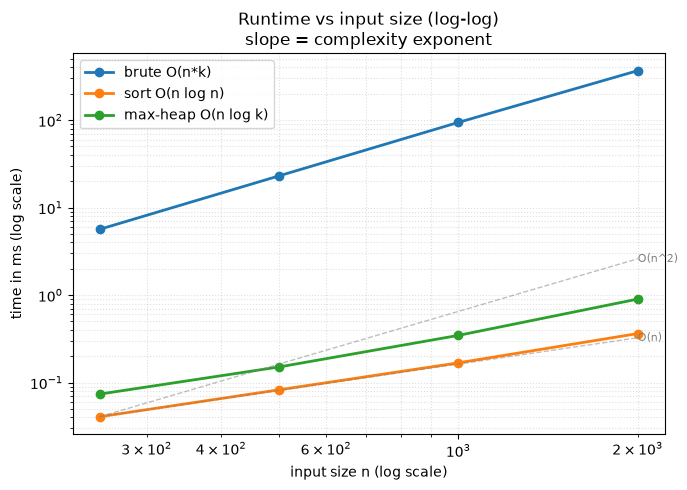

{'brute O(n*k)': [5.642750067636371,
  23.044083965942264,
  94.17883399873972,
  367.96758393757045],
 'sort O(n log n)': [0.04066689871251583,
  0.08262507617473602,
  0.16808300279080868,
  0.36329205613583326],
 'max-heap O(n log k)': [0.0737910158932209,
  0.15070801600813866,
  0.34612498711794615,
  0.9005420142784715]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark


def make_worst_case(n):
    rng = random.Random(n)
    pts = [[rng.randint(-10**4, 10**4), rng.randint(-10**4, 10**4)] for _ in range(n)]
    return (pts, n // 2)                    # k = n/2: the brute force scans n/2 times

solutions = {
    "brute O(n*k)": k_closest_brute,
    "sort O(n log n)": k_closest_sort,
    "max-heap O(n log k)": k_closest_heap,
}
sizes = [250, 500, 1000, 2000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Top K](README.md) — the k **smallest** distances, so the size-k heap is a **max**-heap (negated keys in `heapq`); the farthest kept point is evicted first.
- **Put the priority first in the tuple:** `(-dist, x, y)` so the heap orders by distance.
- **Compare squared distances:** same order as true distance, exact integer math, no `sqrt`.
- **"Any order" answers:** test by sorting both sides; with ties, test the multiset of keys.
- **Signal:** "k closest", "k nearest", "k smallest by some score", "return in any order".
- **Related problems:** Kth Largest Element in a Stream, Kth Largest Element in an Array, Top K Frequent Elements, Find K Closest Elements.
- **Common pitfalls:**
  1. Using a min-heap of all points and popping `k` times — correct, but `O(n)` memory instead of `O(k)`.
  2. Forgetting to negate: a plain min-heap of size k would keep the k **farthest** points.
  3. Pushing `(dist, [x, y])` with equal distances — Python then compares the lists; it works here, but tuples of plain numbers are safer.